# Module 5 — Advanced Analytics and Machine Learning
**Clinical Laboratory Data Engineering & Analytics** · Prasanthi Arikonda (dal574888)

All data in this notebook is read **live from the PostgreSQL warehouse** (`clinical_lab_dw`), which the Python ETL
pipeline filled from MySQL, MongoDB, Excel and CSV. Nothing is copied by hand.

**Business questions answered here**
1. Why did turnaround time (TAT) get worse in Q3 2026?
2. Which tests are likely to be late? *(Model A)*
3. What matters most for being on time — instrument, shift, staffing or test type? *(Model A)*
4. Does night-shift staffing affect delays? *(EDA + Model A)*
5. Is any analyzer behaving abnormally? *(Model C)*

**Contents:** 1 Setup · 2 Load data · 3 KPIs · 4 Exploratory analysis (5 charts) · 5 Model A (Random Forest) · 6 Model C (Isolation Forest) · 7 Findings & limitations

## 1. Setup
Loads the project's own analytics functions (`src/analytics.py`) so the notebook and the Streamlit app use exactly the same calculations.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # make the project's src folder importable

import pandas as pd
import matplotlib.pyplot as plt
import analytics as an

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Setup complete")

Matplotlib is building the font cache; this may take a moment.


Setup complete


## 2. Load the integrated data from the warehouse

In [2]:
df = an.load_lab_tests()
print(f"{len(df):,} ordered tests loaded from dw.fact_lab_test (joined with 6 dimensions + staffing)")
df.head()

4,826 ordered tests loaded from dw.fact_lab_test (joined with 6 dimensions + staffing)


,order_test_id,order_number,priority,test_status,sample_status,rejection_reason,order_datetime,received_at,resulted_at,collect_to_receive_min,...,test_name,category,instrument_code,department_code,department_name,insurance_type,age_group,shift_name,techs_present,staffing_pct
0,14,ORD0000007,STAT,COMPLETED,RECEIVED,NaN,2026-02-18 18:01:00,2026-02-18 18:25:00,2026-02-18 18:42:00,11.0,...,Prothrombin Time,Coagulation,COAG-01,ICU,Intensive Care Unit,Commercial,18-39,Evening,4.0,66.7
1,15,ORD0000007,STAT,COMPLETED,RECEIVED,NaN,2026-02-18 18:01:00,2026-02-18 18:25:00,2026-02-18 18:56:00,11.0,...,International Normalized Ratio,Coagulation,COAG-01,ICU,Intensive Care Unit,Commercial,18-39,Evening,4.0,66.7
2,13,ORD0000007,STAT,COMPLETED,RECEIVED,NaN,2026-02-18 18:01:00,2026-02-18 18:25:00,2026-02-18 18:58:00,11.0,...,Troponin I,Immunoassay,IMMU-01,ICU,Intensive Care Unit,Commercial,18-39,Evening,4.0,66.7
3,21,ORD0000011,ROUTINE,COMPLETED,RECEIVED,NaN,2026-10-02 11:23:00,2026-10-02 13:32:00,2026-10-02 15:26:00,89.0,...,"Vitamin D, 25-Hydroxy",Immunoassay,IMMU-01,ICU,Intensive Care Unit,Self-Pay,18-39,Day,8.0,100.0
4,38,ORD0000018,STAT,COMPLETED,RECEIVED,NaN,2026-02-22 19:12:00,2026-02-22 19:26:00,2026-02-22 19:36:00,5.0,...,Hemoglobin,Hematology,HEME-01,ICU,Intensive Care Unit,Medicaid,40-64,Evening,4.0,100.0


## 3. Business KPIs

In [3]:
kpis = an.compute_kpis(df)
pd.DataFrame(kpis.items(), columns=["KPI", "Value"])

,KPI,Value
0,Tests ordered,4826.00
1,Tests resulted,4623.00
2,Average TAT (min),48.00
3,% within TAT target,85.00
4,% STAT (urgent),25.00
5,Sample rejection rate (%),2.96
6,Abnormal result rate (%),19.30
7,Critical results,38.00
8,Revenue (USD),78145.09


## 4. Exploratory data analysis

### Chart 1 — Monthly average TAT and % of tests within target

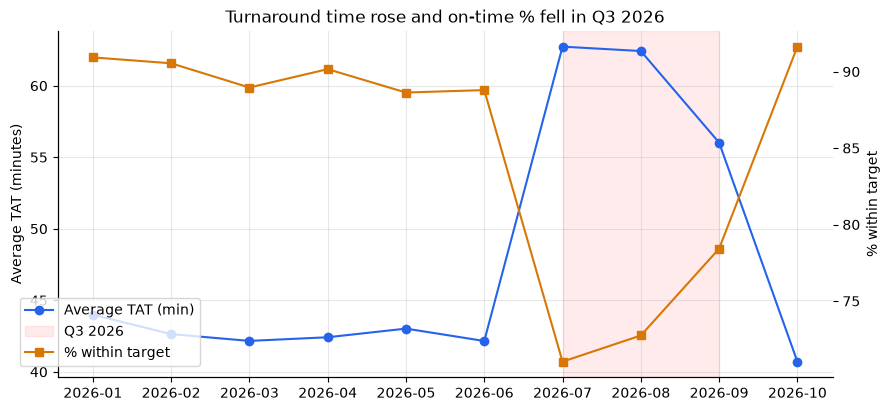

Average TAT by quarter: {1: 42.9, 2: 42.5, 3: 60.6, 4: 40.7}  ->  Q3 is 17.9 minutes slower than Q1-Q2.


In [4]:
resulted = df[df["resulted_at"].notna()]
monthly = (resulted.groupby("year_month")
           .agg(avg_tat=("tat_min", "mean"), pct_on_target=("tat_met", lambda s: 100 * s.astype(bool).mean()))
           .loc["2026-01":"2026-10"])

fig, ax1 = plt.subplots()
ax1.plot(monthly.index, monthly["avg_tat"], marker="o", color="#2563eb", label="Average TAT (min)")
ax1.set_ylabel("Average TAT (minutes)")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["pct_on_target"], marker="s", color="#d97706", label="% within target")
ax2.set_ylabel("% within target"); ax2.grid(False)
ax1.axvspan("2026-07", "2026-09", color="red", alpha=0.08, label="Q3 2026")
ax1.set_title("Turnaround time rose and on-time % fell in Q3 2026")
fig.legend(loc="lower left", bbox_to_anchor=(0.08, 0.12)); plt.show()

q = resulted.groupby("quarter")["tat_min"].mean().round(1)
print(f"Average TAT by quarter: {q.to_dict()}  ->  Q3 is {q[3] - q[[1, 2]].mean():.1f} minutes slower than Q1-Q2.")

### Chart 2 — Which instrument caused it? Chemistry TAT by analyzer and month

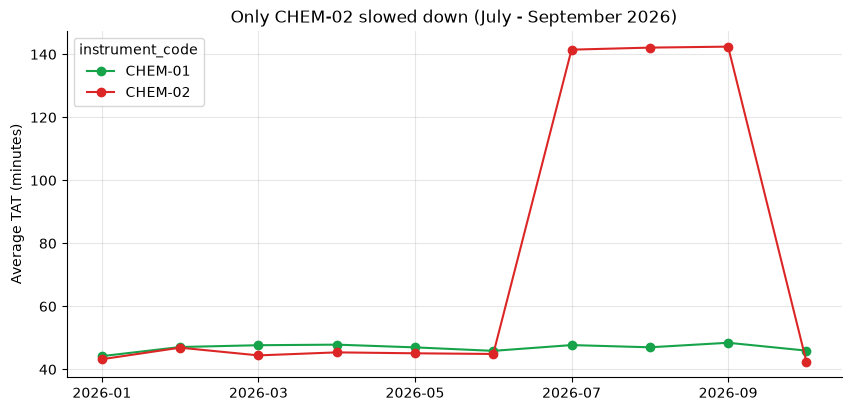

Q3 chemistry TAT: {'CHEM-01': 47.7, 'CHEM-02': 141.9}


In [5]:
chem = resulted[resulted["category"] == "Chemistry"]
pivot = chem.pivot_table(index="year_month", columns="instrument_code", values="tat_min", aggfunc="mean").loc["2026-01":"2026-10"]
pivot.plot(marker="o", color=["#16a34a", "#dc2626"])
plt.title("Only CHEM-02 slowed down (July - September 2026)"); plt.ylabel("Average TAT (minutes)"); plt.xlabel("")
plt.show()
q3 = chem[chem["quarter"] == 3].groupby("instrument_code")["tat_min"].mean().round(1)
print(f"Q3 chemistry TAT: {q3.to_dict()}")

### Chart 3 — Shift, staffing and delays

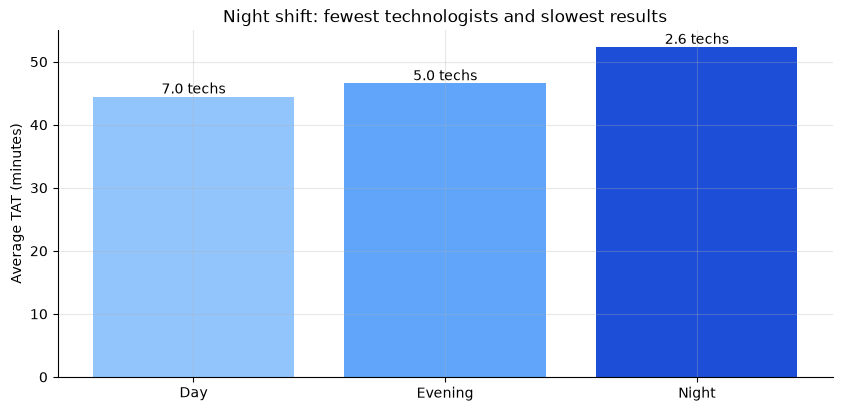

            avg_tat  techs
shift_name                
Day            44.5    7.0
Evening        46.6    5.0
Night          52.3    2.6


In [6]:
shift = (resulted.groupby("shift_name")
         .agg(avg_tat=("tat_min", "mean"), techs=("techs_present", "mean"))
         .reindex(["Day", "Evening", "Night"]))
fig, ax = plt.subplots()
bars = ax.bar(shift.index, shift["avg_tat"], color=["#93c5fd", "#60a5fa", "#1d4ed8"])
for b, t in zip(bars, shift["techs"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f"{t:.1f} techs", ha="center")
ax.set_ylabel("Average TAT (minutes)"); ax.set_title("Night shift: fewest technologists and slowest results")
plt.show()
print(shift.round(1))

### Chart 4 — Why are samples rejected?

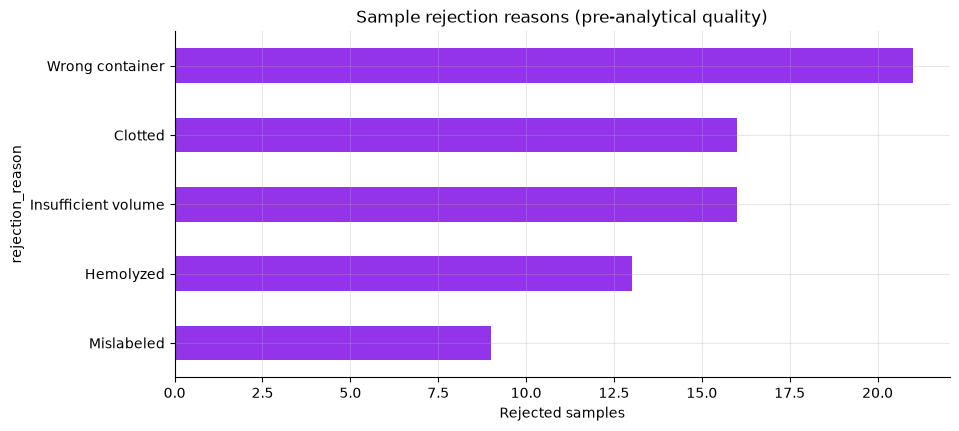

In [7]:
rej = (df[df["sample_status"] == "REJECTED"].drop_duplicates("order_number")
       ["rejection_reason"].value_counts().sort_values())
rej.plot(kind="barh", color="#9333ea")
plt.title("Sample rejection reasons (pre-analytical quality)"); plt.xlabel("Rejected samples"); plt.show()

### Chart 5 — Monthly revenue by insurance type (external Excel fee schedule)

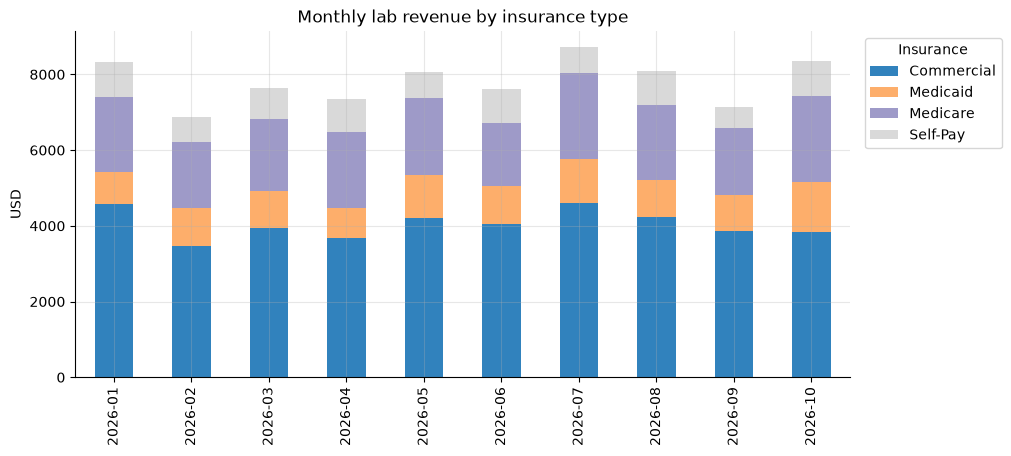

Total revenue: $78,145; largest payer: Commercial


In [8]:
rev = (df.pivot_table(index="year_month", columns="insurance_type", values="reimbursement_usd", aggfunc="sum")
       .loc["2026-01":"2026-10"])
rev.plot(kind="bar", stacked=True, colormap="tab20c")
plt.title("Monthly lab revenue by insurance type"); plt.ylabel("USD"); plt.xlabel("")
plt.legend(title="Insurance", bbox_to_anchor=(1.01, 1), loc="upper left"); plt.show()
print(f"Total revenue: ${df['reimbursement_usd'].sum():,.0f}; largest payer: {rev.sum().idxmax()}")

## 5. Model A — Random Forest: *"Will this test miss its turnaround-time target?"*

| | |
|---|---|
| **Business question** | Which tests are likely to be late, and what drives delays? |
| **Type** | Supervised classification (late = 1, on time = 0) |
| **Target** | `tat_met = FALSE` → the result took longer than the test's target time |
| **Inputs (9)** | test category, priority, instrument, shift, day of week, department, transport method, month, staffing % on that shift — all known **when the sample arrives** |
| **Not used** | the actual TAT minutes (that would be *data leakage*: the answer hidden in the question) |
| **Baseline** | Logistic Regression — a simple model; Random Forest must beat it to be worth using |
| **Evaluation** | 75% of tests train the model, the other 25% (never seen) test it. Accuracy, precision, recall, F1 and ROC-AUC |
| **Class balance** | Only a minority of tests are late, so `class_weight="balanced"` makes the model pay attention to them |

In [9]:
result = an.train_delay_model(df)
print(f"Training rows: {result['n_train']:,}   Test rows: {result['n_test']:,}   Late rate: {100*result['late_rate']:.1f}%\n")
result["metrics"]

Training rows: 3,466   Test rows: 1,156   Late rate: 15.0%



,Accuracy,Precision (late),Recall (late),F1 (late),ROC-AUC
Logistic Regression (baseline),0.749,0.359,0.861,0.507,0.869
Random Forest,0.768,0.378,0.850,0.523,0.899


**How to read these scores:** *Recall (late)* = of the tests that really were late, how many did the model catch. *Precision (late)* = of the tests the model warned about, how many really were late. *ROC-AUC* = how well the model ranks risky tests above safe ones (0.5 = guessing, 1.0 = perfect).

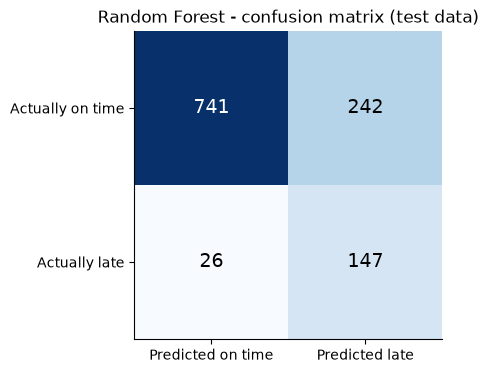

Caught 147 of 173 late tests (85%). 242 on-time tests were flagged as risky (false alarms).


In [10]:
cm = result["confusion_matrix"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in pd.DataFrame(cm).stack().items():
    ax.text(j, i, v, ha="center", va="center", fontsize=14, color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predicted on time", "Predicted late"]); ax.set_yticks([0, 1], ["Actually on time", "Actually late"])
ax.set_title("Random Forest - confusion matrix (test data)"); ax.grid(False); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp} of {tp + fn} late tests ({100*tp/(tp+fn):.0f}%). {fp} on-time tests were flagged as risky (false alarms).")

### What matters most? (permutation importance)
Each input is shuffled in turn; the bigger the drop in ROC-AUC, the more the model relies on it.

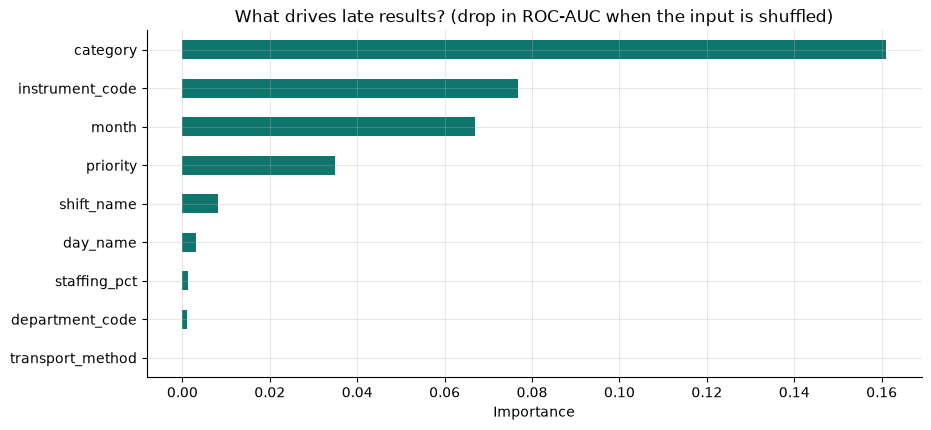

Top drivers of delay: category, instrument_code, month


In [11]:
imp = result["importance"].sort_values()
imp.plot(kind="barh", color="#0f766e")
plt.title("What drives late results? (drop in ROC-AUC when the input is shuffled)"); plt.xlabel("Importance"); plt.show()
top = result["importance"].index[:3].tolist()
print(f"Top drivers of delay: {', '.join(top)}")

In [12]:
model = result["model"]
# Note: because the model was trained with balanced classes, these are RELATIVE risk scores
# (useful for ranking), not exact real-world probabilities.
for group in ["instrument_code", "shift_name", "priority"]:
    print(f"\nAverage predicted chance of being late, by {group}:")
    print(an.late_risk_by_group(model, df, group).to_string())


Average predicted chance of being late, by instrument_code:
instrument_code
IMMU-02    66.1
IMMU-01    62.5
CHEM-02    59.8
CHEM-01    48.4
COAG-01    16.0
HEME-02     2.3
URIN-01     1.8
HEME-01     0.9

Average predicted chance of being late, by shift_name:
shift_name
Night      32.8
Evening    30.4
Day        29.7

Average predicted chance of being late, by priority:
priority
ROUTINE    35.6
STAT       16.9


**Business interpretation (Model A)**
- The model clearly beats random guessing and the Logistic Regression baseline on ROC-AUC, so it ranks risky tests well.
- **Test category** matters most: some tests (e.g. troponin, chemistry STAT panels) have tight targets.
- **Instrument together with month** is the next driver — the model learned that CHEM-02 in July–September was a high-risk combination, the same problem seen in Charts 1–2. The immunoassay analyzers also score high because troponin has a strict 60-minute target.
- **Night shift** carries the highest average predicted risk, consistent with Chart 3 (fewest technologists).
- **Use in the lab:** score each sample on arrival and move high-risk samples to the front of the queue or to a backup analyzer.
- The model favors **catching** late tests (high recall) at the cost of some false alarms — acceptable because a false alarm only means a sample is prioritized.

## 6. Model C — Isolation Forest: *"Is this analyzer behaving abnormally?"*

| | |
|---|---|
| **Business question** | Is any analyzer starting to fail? (early warning) |
| **Type** | Unsupervised anomaly detection — **no labels needed** |
| **Unit analysed** | one instrument × one week (weekly totals are less noisy than single days) |
| **Inputs (5)** | error events, downtime minutes, QC failures (all from MongoDB logs), tests resulted, average TAT |
| **How** | each value is compared with *that instrument's own normal level* (median-based z-score), then Isolation Forest flags the 5% most unusual instrument-weeks |
| **Evaluation** | the incident reports document a real problem (CHEM-02, July–September). We check whether the model finds those weeks **without being told** |

In [13]:
weeks = an.load_instrument_weeks()
flagged = an.detect_instrument_anomalies(weeks, contamination=0.05)
pd.DataFrame(an.anomaly_evaluation(flagged).items(), columns=["Check", "Result"])

,Check,Result
0,Instrument-weeks analysed,352.0
1,Weeks flagged as abnormal,18.0
2,Known CHEM-02 problem weeks (Jul-Sep),14.0
3,Problem weeks found by the model,14.0
4,Recall: % of problem weeks found,100.0
5,Precision: % of flags that were real problems,77.8


In [ ]:
print("Weeks flagged as abnormal (most unusual first):")
cols = ["instrument_code", "week", "error_events", "downtime_min", "qc_failures", "avg_tat_min", "anomaly_score"]
flagged[flagged["is_anomaly"]].sort_values("anomaly_score", ascending=False)[cols].round({"avg_tat_min": 1, "anomaly_score": 3})

Weeks flagged as abnormal (most unusual first):


,instrument_code,week,error_events,downtime_min,qc_failures,avg_tat_min,anomaly_score
72,CHEM-02,2026-07-13,9.0,561.0,3.0,130.5,0.716
70,CHEM-02,2026-06-29,7.0,457.0,1.0,97.7,0.704
82,CHEM-02,2026-09-21,3.0,186.0,2.0,113.1,0.691
74,CHEM-02,2026-07-27,3.0,257.0,5.0,135.4,0.689
347,URIN-01,2026-09-28,2.0,38.0,2.0,29.4,0.675
79,CHEM-02,2026-08-31,6.0,387.0,5.0,115.9,0.673
77,CHEM-02,2026-08-17,3.0,215.0,4.0,118.5,0.670
75,CHEM-02,2026-08-03,6.0,464.0,3.0,147.3,0.665
81,CHEM-02,2026-09-14,6.0,365.0,2.0,124.2,0.663
78,CHEM-02,2026-08-24,6.0,408.0,4.0,110.9,0.657


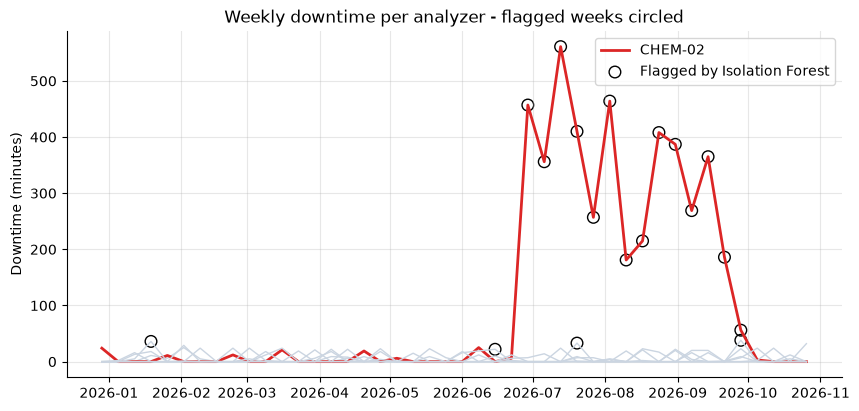

In [ ]:
fig, ax = plt.subplots()
for code_, grp in flagged.groupby("instrument_code"):
    ax.plot(grp["week"], grp["downtime_min"], color="#dc2626" if code_ == "CHEM-02" else "#cbd5e1",
            lw=2 if code_ == "CHEM-02" else 1, label="CHEM-02" if code_ == "CHEM-02" else None)
hits = flagged[flagged["is_anomaly"]]
ax.scatter(hits["week"], hits["downtime_min"], s=70, facecolors="none", edgecolors="black", label="Flagged by Isolation Forest")
ax.set_title("Weekly downtime per analyzer - flagged weeks circled"); ax.set_ylabel("Downtime (minutes)")
ax.legend(); plt.show()

**Business interpretation (Model C)**
- Without any labels, the model singled out **CHEM-02 in July–September** — matching the incident reports and the TAT drop in Charts 1–2.
- It also flagged a few single weeks on other analyzers; these are worth a quick look but are isolated, not a trend.
- **Use in the lab:** run weekly; a flagged analyzer is reviewed (QC, maintenance) *before* turnaround time collapses.
- In this data the problem began in early July; a weekly alert would have triggered within the first week instead of after three months.

## 7. Findings and limitations

**Answer to the executive question — why did TAT get worse in Q3 2026?**
1. *Measured fact:* average TAT rose from about **42.7 minutes in Q1–Q2 to 60.6 minutes in Q3** (+17.9 min), and the share of tests within target fell from ~90% to **73.9%** (Chart 1, warehouse SQL Q2).

2. *Measured fact:* the increase came from chemistry analyzer **CHEM-02**, whose Q3 TAT was **141.9 minutes vs 47.7 for CHEM-01** (Chart 2, SQL Q3). In July–September CHEM-02 logged **68 error events and about 4,500 minutes of downtime** (MongoDB → warehouse, SQL Q4).

3. *Model evidence:* Isolation Forest independently flagged **all 14 of CHEM-02's problem weeks** (100% recall, 77.8% precision) without labels; Random Forest (**ROC-AUC 0.899**, catches **85%** of late tests) ranks test category, instrument and month as the top delay drivers.

4. *Secondary factor:* night shifts have the fewest technologists (**2.6 vs 7.0 on day shift**) and the slowest TAT (**52.3 vs 44.5 minutes**).

**Limitations**
- Data is **synthetic** (required for healthcare by the handbook); real data would be noisier and patterns weaker.
- Model A uses a random train/test split; a production version should train on past months and test on later months.
- Model A's precision is moderate (false alarms) — tuned on purpose to catch most late tests.
- Model C's 5% threshold is a choice; a real lab would tune it with supervisors to balance alerts vs. workload.
- Correlation is not causation: models show *associations*. The incident reports (used by RAG in Module 6) provide the documented cause.
- Not modelled: test-volume forecasting and rejection prediction — in this data those events are random, so a model would learn only noise.